# 16.7 - Frontal alignment annotation pilot

Prepare a local review packet. Candidate photographs are not confirmed frontal views or target labels. Do not publish images while redistribution terms are unverified.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
root = Path.cwd().resolve()
while not (root / "AGENTS.md").exists():
    if root == root.parent: raise RuntimeError("Project root not found")
    root = root.parent
pilot = root / "data/processed/alignment_omni_pilot"
source = pd.read_csv(pilot / "pilot_provenance.csv", dtype={"source_image_id": str, "sha256": str})
print("Pilot records:", len(source))
display(source.groupby("split").size().to_frame("images"))

Pilot records: 36


,images
split,
train,26
val,10


## Verify source images

Check SHA-256 and dimensions for each image; preserve the source split. A filename suffix is only a prioritization heuristic.

In [2]:
records = []
for r in source.to_dict("records"):
    path = pilot / "images" / r["split"] / (r["source_image_id"] + ".jpg")
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == r["sha256"], f"Hash mismatch: {path}"
    with Image.open(path) as im: width, height = im.size
    records.append({**r, "image_path": path.relative_to(root).as_posix(), "width": width, "height": height})
verified = pd.DataFrame(records)
assert len(verified) == 36 and not verified.sha256.duplicated().any()
print("Verified images:", len(verified))
display(verified.groupby("split")[["width", "height"]].agg(["min", "median", "max"]))

Verified images: 36


width             height            
        min median  max    min median  max
split                                     
train   512  512.0  512    341  341.0  341
val     512  512.0  512    341  341.0  341

## Prepare review and annotation files

A reviewer must independently determine view and target status. Record present, absent or uncertain; an omitted box does not mean absent. Review the pilot with a dental professional before bulk annotation. Existing review files are never overwritten.

In [3]:
out = root / "docs/reports/alignment/frontal_pilot_16_7"
out.mkdir(parents=True, exist_ok=True)
queue = verified[["split", "source_image_id", "image_path", "sha256", "width", "height"]].copy()
for field in ["view_review", "dentition_review", "diastema_review", "crowding_review", "reviewer", "review_notes"]: queue[field] = "pending"
queue_path = out / "review_queue.csv"
if not queue_path.exists(): queue.to_csv(queue_path, index=False)
else: print("Preserving existing review queue")
box_path = out / "boxes_template.csv"
if not box_path.exists():
    pd.DataFrame(columns=["source_image_id", "target", "x_min", "y_min", "x_max", "y_max", "reviewer", "review_state", "notes"]).to_csv(box_path, index=False)
else: print("Preserving existing box annotations")
display(queue.head())

,split,source_image_id,image_path,sha256,width,height,view_review,dentition_review,diastema_review,crowding_review,reviewer,review_notes
0,train,201815201808161,data/processed/alignment_omni_pilot/images/tra...,58d1cca4dfa451313a66a24b136ceebd590e3dd5ed1e77...,512,341,pending,pending,pending,pending,pending,pending
1,train,201823201808031,data/processed/alignment_omni_pilot/images/tra...,f23e6090093fafad3ff04957a27a02010b035c86355f61...,512,341,pending,pending,pending,pending,pending,pending
2,train,201831201808031,data/processed/alignment_omni_pilot/images/tra...,1ee34ed26c2fad6377598f114440a2f3652bfbb5e50a28...,512,341,pending,pending,pending,pending,pending,pending
3,train,201834201808071,data/processed/alignment_omni_pilot/images/tra...,5c526d2453f5e7512d11e4bd3fb21b6850aa3ab959167f...,512,341,pending,pending,pending,pending,pending,pending
4,train,201838201808091,data/processed/alignment_omni_pilot/images/tra...,f7f2d4eac076a29e7554f8c5a7bf29d9146c5c5d6647ba...,512,341,pending,pending,pending,pending,pending,pending


## Annotation protocol

Use original-image pixel coordinates. For upper midline diastema, include the central incisors surrounding the visible gap. For anterior crowding, include affected anterior teeth and their neighbors. Record uncertain cases rather than guessing. This working protocol is adapted from [the YOLO11 malocclusion study](https://pmc.ncbi.nlm.nih.gov/articles/PMC12839579/) and must be reviewed for this dataset.

## Contact sheets

Examine each candidate for frontal suitability and image quality. These local sheets are review aids, not model predictions or clinical labels.

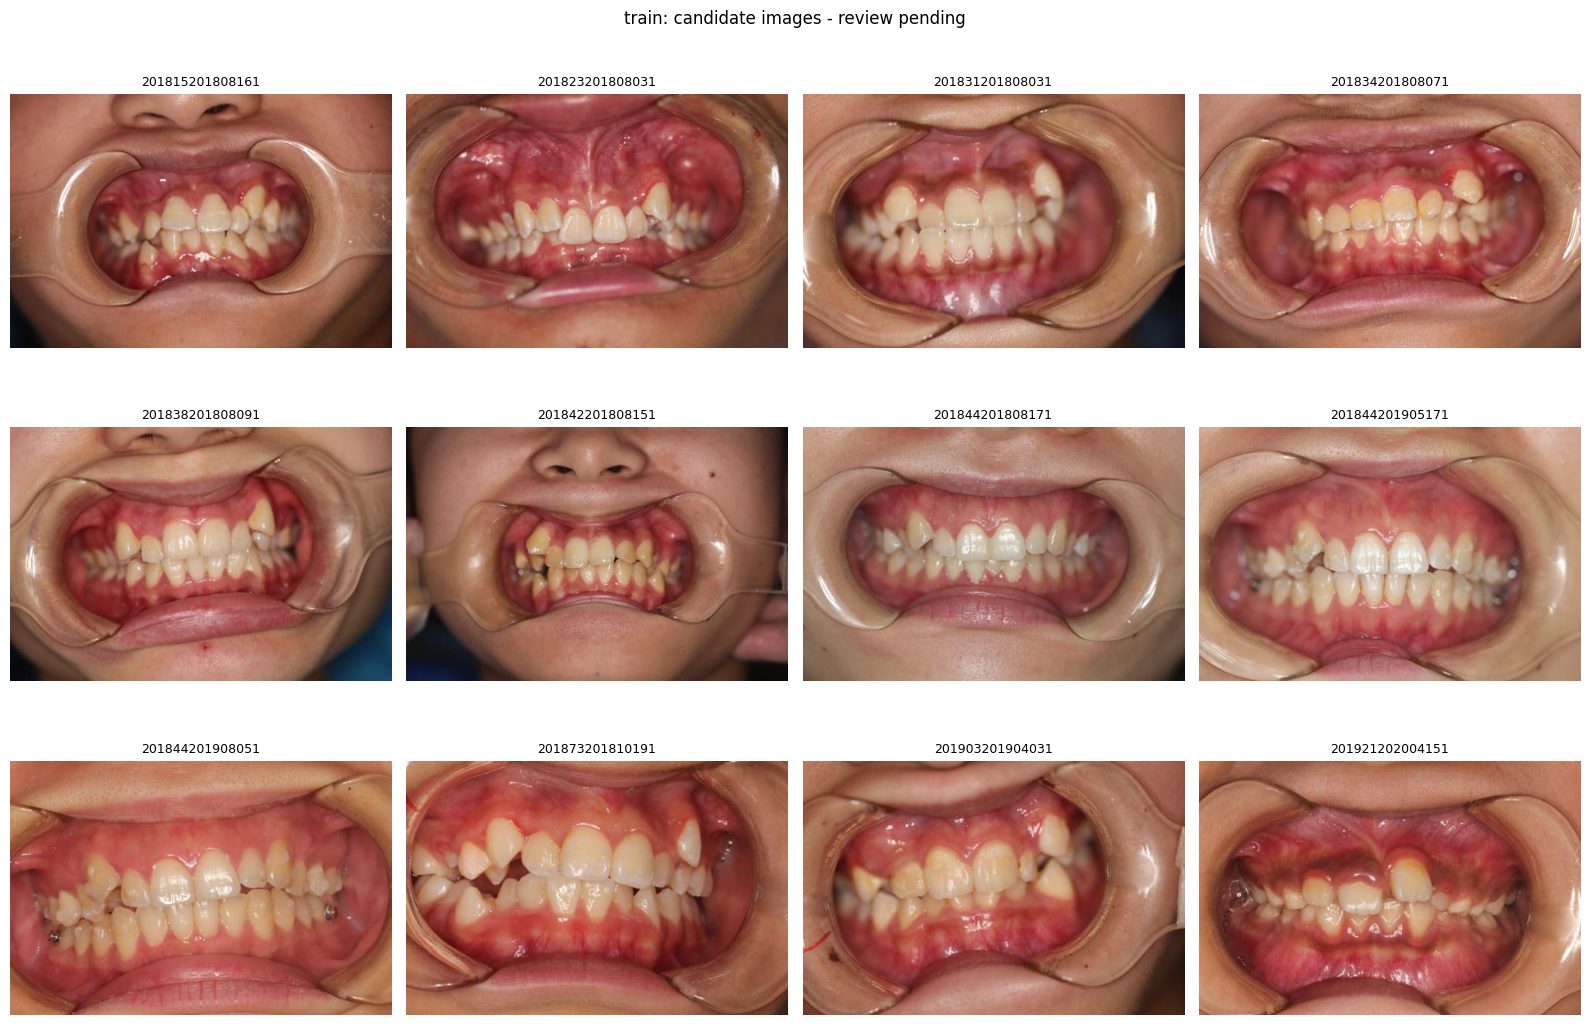

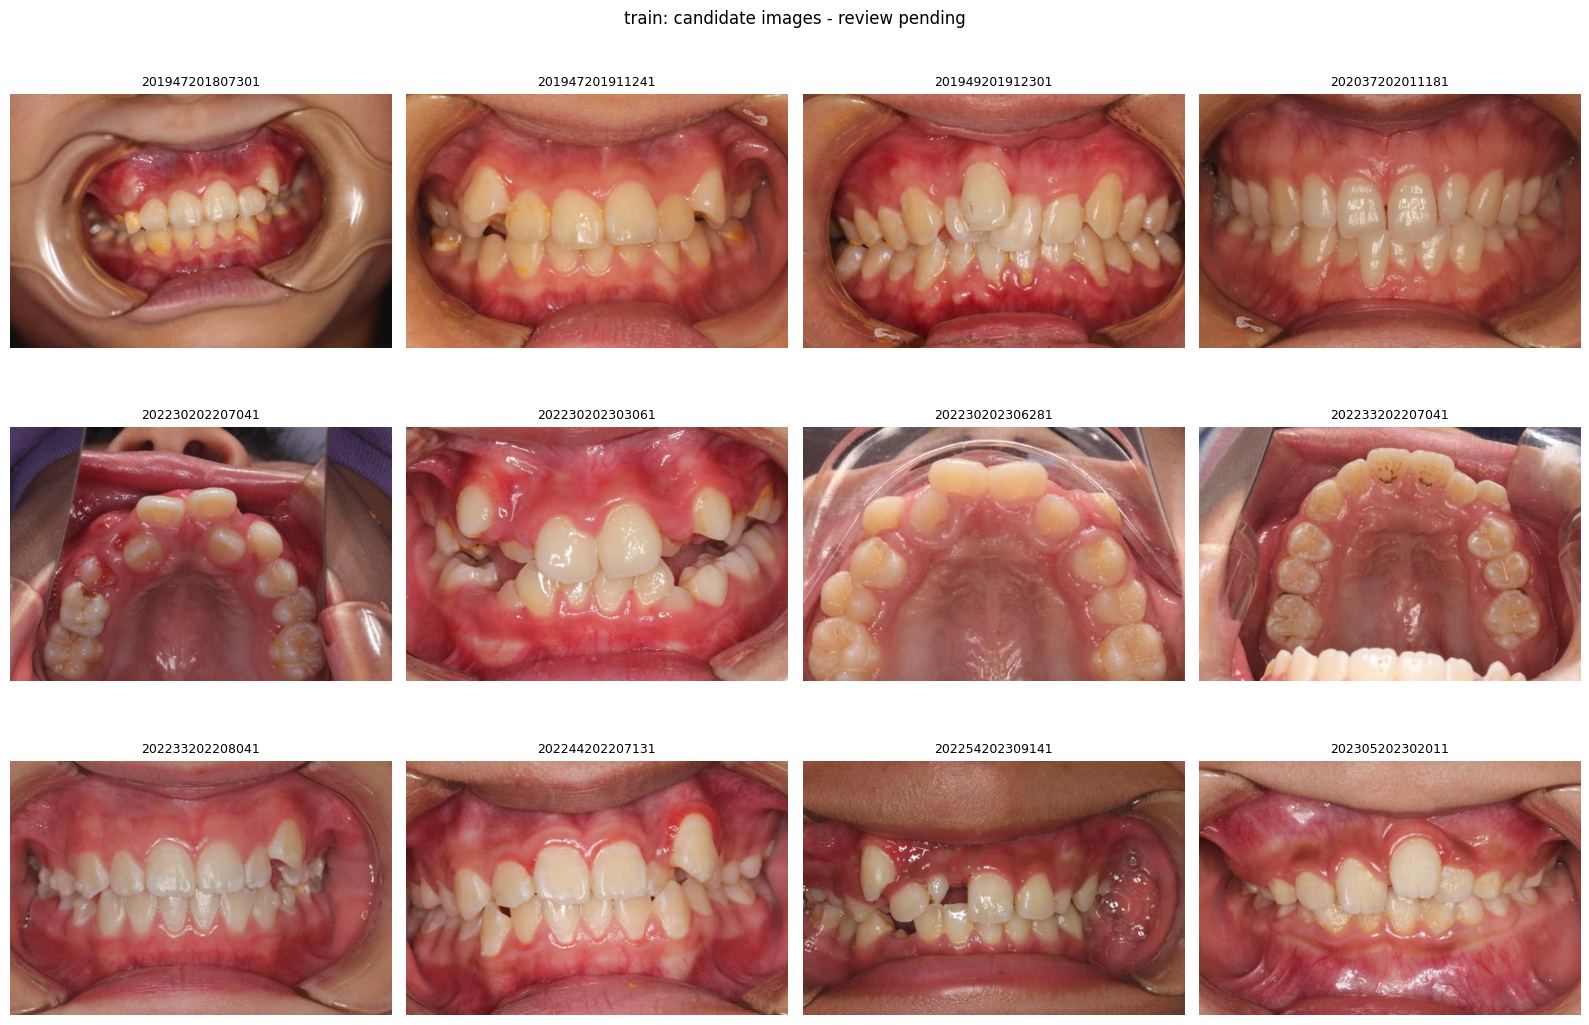

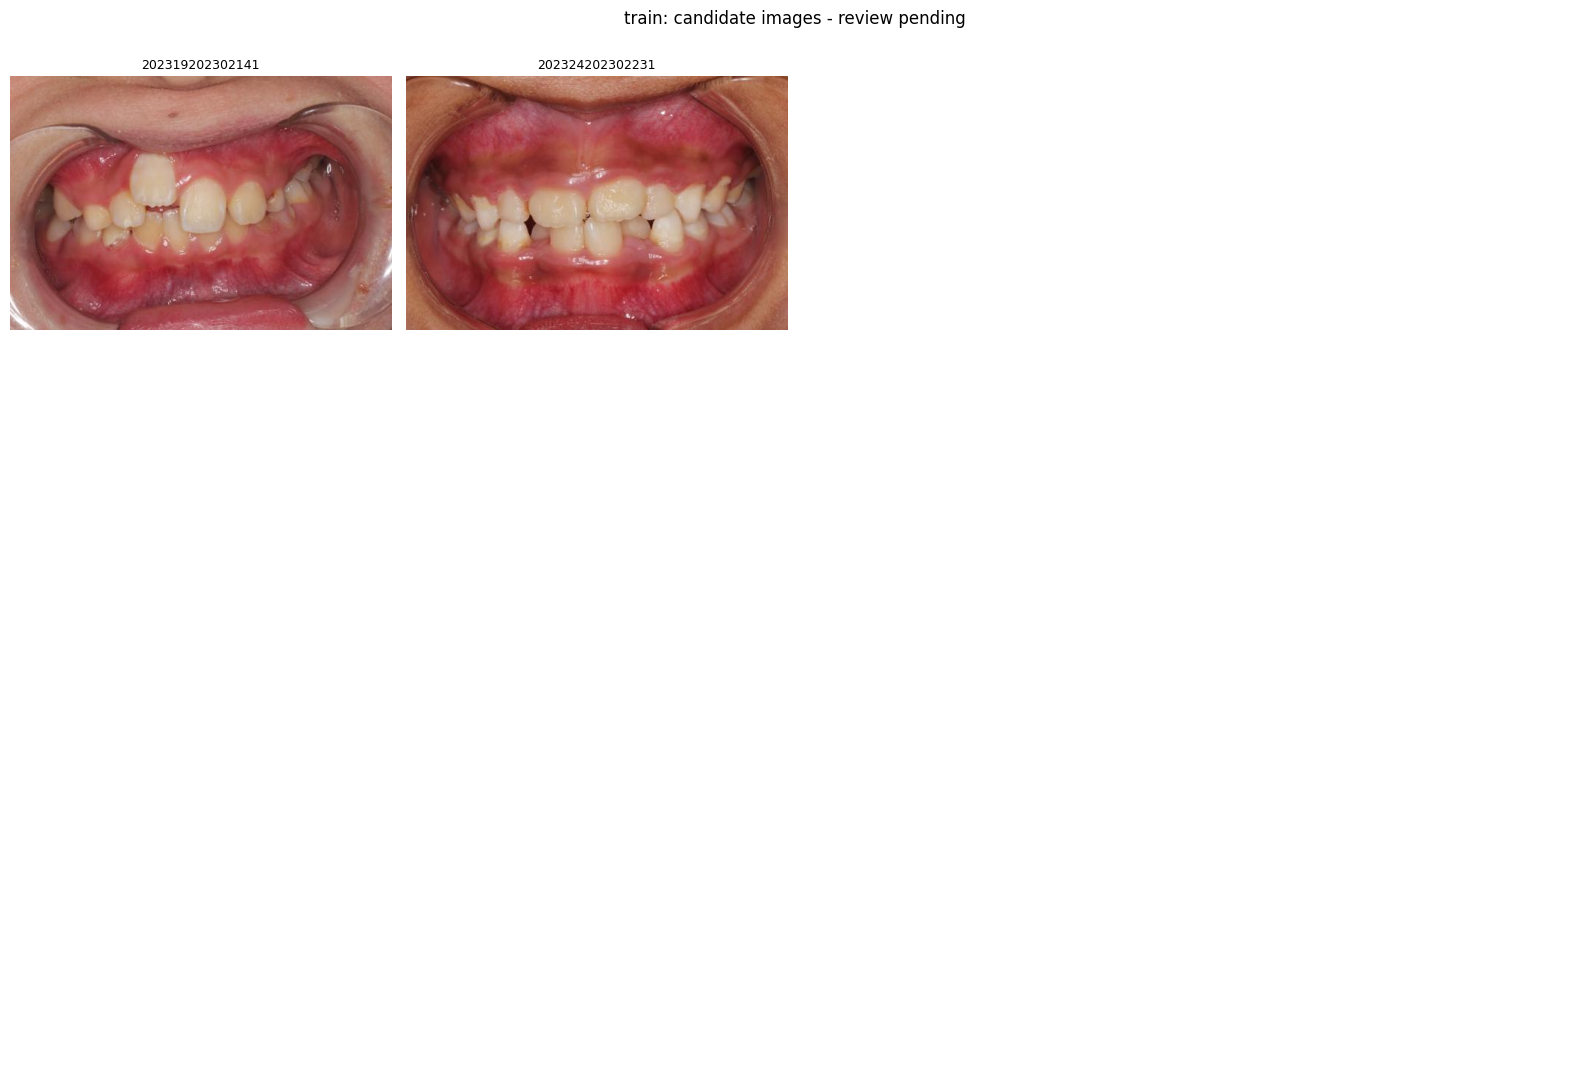

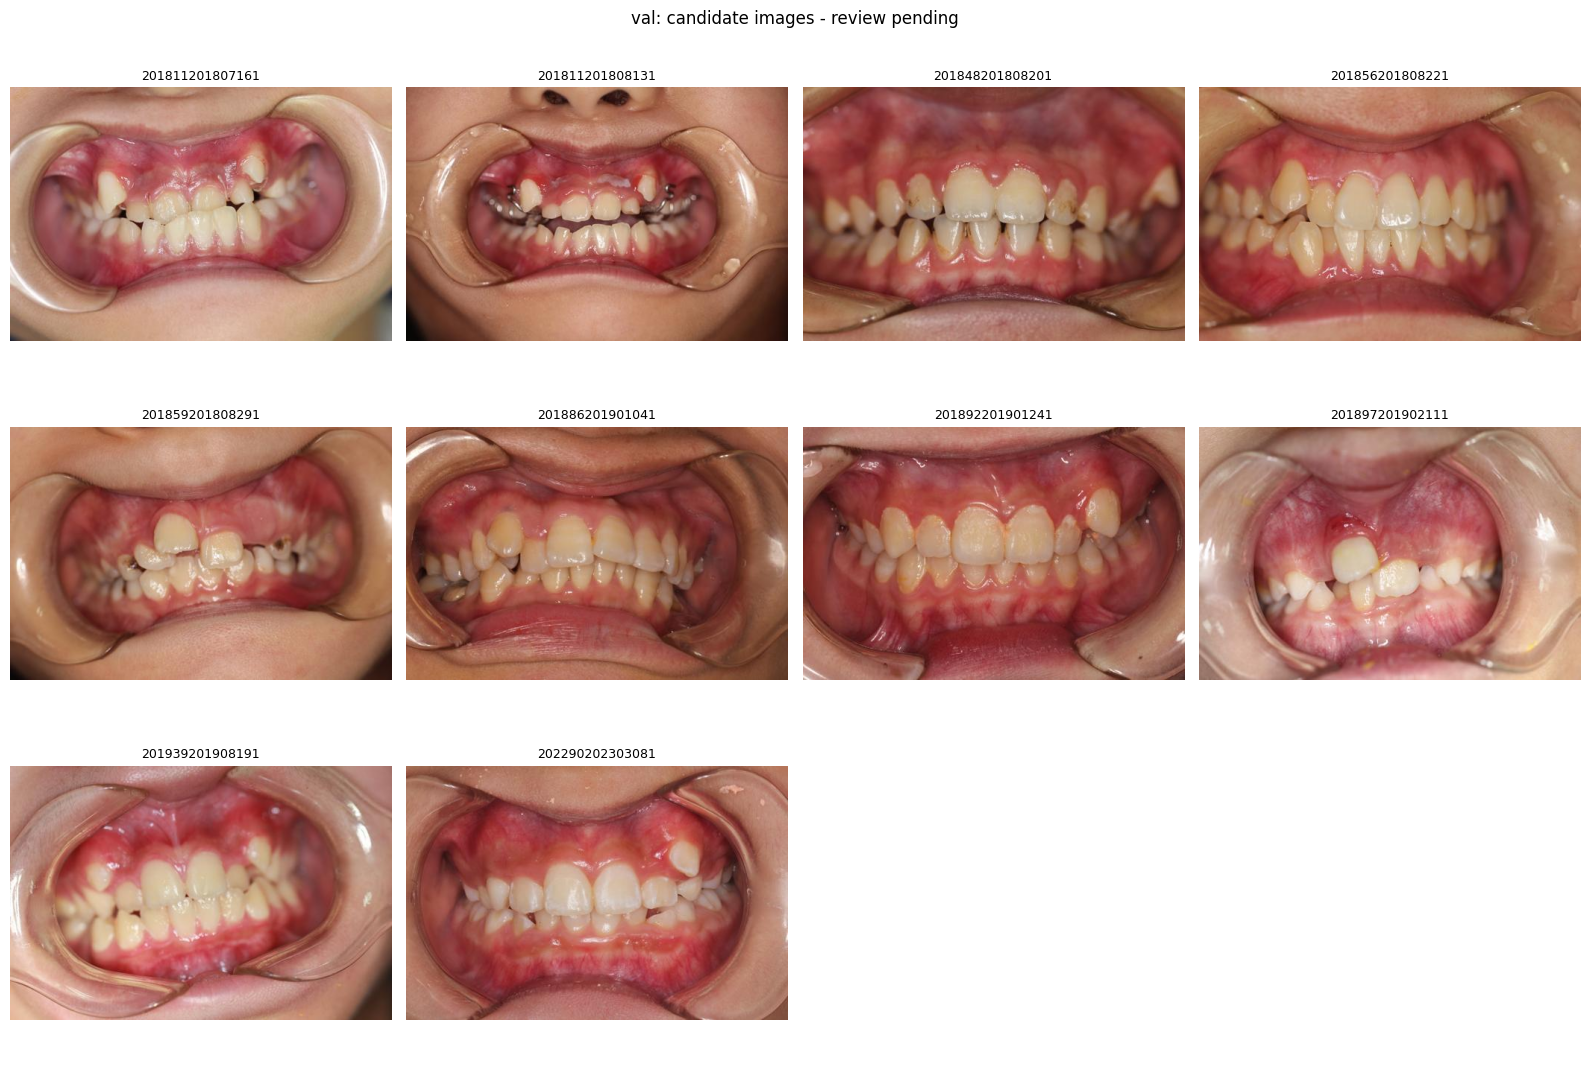

Review packet: C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\frontal_pilot_16_7


In [4]:
for split, group in verified.groupby("split"):
    for start in range(0, len(group), 12):
        chunk = group.iloc[start:start + 12]
        fig, axes = plt.subplots(3, 4, figsize=(16, 11))
        axes = axes.flatten()
        for ax, (_, row) in zip(axes, chunk.iterrows()):
            ax.imshow(Image.open(root / row.image_path))
            ax.set_title(row.source_image_id, fontsize=9)
            ax.axis("off")
        for ax in axes[len(chunk):]: ax.axis("off")
        fig.suptitle(f"{split}: candidate images - review pending")
        fig.tight_layout()
        fig.savefig(out / f"{split}_{start // 12 + 1}.png", dpi=120)
        plt.show()
        plt.close(fig)
print("Review packet:", out)